<a href="https://colab.research.google.com/github/BasSarayut/AI/blob/main/thai-food-calorie/notebooks/train_yolo_thai_food.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Thai Food Calorie Estimator: Train YOLO บน Google Colab

Notebook นี้จะพาคุณ train โมเดล **YOLO** ให้รู้จักอาหารไทย แล้วนำผลมาประมาณแคลอรี่ ตั้งแต่ขั้นแรกจนได้โมเดลไปใช้ใน demo

```
รูปอาหาร → YOLO (ตรวจจับว่าเป็นเมนูอะไร อยู่ตรงไหน) → ตาราง nutrition.csv → แคลอรี่รวม (เป็นช่วง ±)
```

**สิ่งที่จะได้เรียนรู้:** GPU, dataset แบบ YOLO, transfer learning, epoch/batch, overfitting, mAP/precision/recall, domain shift และการวัดผลด้วย ground truth จริง

### เตรียมก่อนเริ่ม
1. **เปิด GPU:** เมนู `Runtime → Change runtime type → T4 GPU`
2. สมัครบัญชี [Roboflow](https://roboflow.com) (ฟรี) แล้วคัดลอก API key จาก Settings
3. สมัครบัญชี [Hugging Face](https://huggingface.co) (ฟรี) แล้วสร้าง Access Token แบบ **Write**
4. กดไอคอนกุญแจ (**Secrets**) ด้านซ้าย เพิ่ม `ROBOFLOW_API_KEY` กับ `HF_TOKEN` แล้วเปิด "Notebook access"

> **ห้ามวาง API key ลงในโค้ดตรงๆ** เพราะ notebook นี้จะถูกแชร์เป็น portfolio ใครเปิดก็เห็น key ของคุณ ให้ใช้ Secrets เสมอ

## ขั้นที่ 1: เช็กว่าได้ GPU จริง

การ train โมเดลคือการคำนวณเมทริกซ์จำนวนมหาศาลซ้ำๆ GPU ทำงานแบบขนานได้เป็นพันคอร์ จึงเร็วกว่า CPU หลายสิบเท่า
ถ้าคำสั่งด้านล่าง error หรือไม่เห็น `Tesla T4` ให้กลับไปเปิด GPU ตามขั้นเตรียม (บางช่วง Colab ฟรีอาจไม่มี GPU ว่าง ต้องรอแล้วลองใหม่)

In [28]:
!nvidia-smi

Thu Oct 29 12:01:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P0             26W /   70W |    1009MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## ขั้นที่ 2: เชื่อม Google Drive

ไฟล์ใน Colab **จะหายหมดเมื่อ session จบ** (ปิดแท็บ ไม่ได้ใช้งานนานๆ หรือครบเวลา) เราจึงเก็บ dataset และผล train ไว้ใน Drive

In [29]:
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
DRIVE_DIR = Path('/content/drive/MyDrive/thai-food-calorie')
DRIVE_DIR.mkdir(parents=True, exist_ok=True)
print('เก็บไฟล์ไว้ที่', DRIVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
เก็บไฟล์ไว้ที่ /content/drive/MyDrive/thai-food-calorie


## ขั้นที่ 3: ติดตั้ง library และดึงโค้ดโปรเจกต์

ระบุเวอร์ชันให้ชัด (`==`) เพื่อให้คนอื่นเปิด notebook นี้แล้วได้ผลเหมือนคุณ ถ้าไม่ระบุ library อาจอัปเดตแล้วโค้ดพัง

โค้ดอยู่ใน repo [BasSarayut/AI](https://github.com/BasSarayut/AI) โฟลเดอร์ `thai-food-calorie/` ถ้าแก้ไฟล์ใน repo (เช่น `nutrition.csv`) แล้ว push ให้รัน cell นี้ใหม่เพื่อดึงเวอร์ชันล่าสุด

In [30]:
!pip install -q ultralytics==8.4.181 roboflow==1.7.1 huggingface_hub==2.2.0

In [31]:
import sys

REPO_URL = 'https://github.com/BasSarayut/AI.git'
REPO_DIR = Path('/content/AI')
PROJECT_DIR = REPO_DIR / 'thai-food-calorie'
if REPO_DIR.exists():
    !git -C {REPO_DIR} pull
else:
    !git clone {REPO_URL} {REPO_DIR}
%cd {PROJECT_DIR}
sys.path.insert(0, str(PROJECT_DIR))

remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 5 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 3.37 MiB | 5.19 MiB/s, done.
From https://github.com/BasSarayut/AI
   175e80a..a60d8ed  main       -> origin/main
Updating 175e80a..a60d8ed
Fast-forward
 .../notebooks/train_yolo_thai_food.ipynb           | 1931 +++++++++++++++-----
 1 file changed, 1453 insertions(+), 478 deletions(-)
/content/AI/thai-food-calorie


## ขั้นที่ 4: ดาวน์โหลด dataset

ใช้ dataset [Thai_food บน Roboflow Universe](https://universe.roboflow.com/thaifood/thai_food-y98fg) (ราว 600 ภาพ มี bounding box แล้ว)

**Dataset แบบ YOLO มีหน้าตาแบบนี้:**
```
train/images/xxx.jpg   ← รูป
train/labels/xxx.txt   ← 1 บรรทัดต่อ 1 วัตถุ: class_id x_center y_center width height (ค่า 0-1 เทียบกับขนาดรูป)
valid/ ...             ← ใช้วัดผลระหว่าง train
test/  ...             ← ใช้วัดผลครั้งสุดท้าย (โมเดลไม่เคยเห็น)
data.yaml              ← บอกว่าไฟล์อยู่ไหน มีกี่ class ชื่ออะไร
```

**ทำไมต้องแบ่ง train/valid/test?** เหมือนการสอบ ถ้าเอาข้อสอบจริงมาให้ท่องก่อน คะแนนจะสูงเกินจริง โมเดลก็เช่นกัน ต้องวัดผลกับรูปที่ไม่เคยเห็น

**ใช้ dataset จากไหน:** ค่าเริ่มต้นคือดาวน์โหลดจาก Universe (ต้นฉบับ) ถ้าคุณ fork ไป workspace ของตัวเองและกด Generate version แล้ว ให้เปลี่ยน 3 ตัวแปรด้านบนของ cell ถัดไปเป็นของ fork
หาค่าได้จาก URL: `app.roboflow.com/<WORKSPACE>/<PROJECT>/<VERSION>` (format เดียวกันใช้ได้กับ YOLO ทุกรุ่นของ Ultralytics)

In [32]:
import yaml
from google.colab import userdata
from roboflow import Roboflow

ROBOFLOW_WORKSPACE = 'thaifood'
ROBOFLOW_PROJECT = 'thai_food-y98fg'
ROBOFLOW_VERSION = None

rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY'))
project = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT)
available = sorted(int(v.version) for v in project.versions())
print('versions ที่มี:', available)
if not available:
    raise RuntimeError(f'{ROBOFLOW_PROJECT} ยังไม่มี version: เข้า Roboflow แล้วกด Generate ก่อน')
version = ROBOFLOW_VERSION or available[-1]
print('ใช้ version', version)
dataset = project.version(version).download(
    'yolov8', location=str(DRIVE_DIR / 'datasets' / ROBOFLOW_PROJECT))

DATA_ROOT = Path(dataset.location)
DATA_YAML = DATA_ROOT / 'data.yaml'
HAS_TEST = (DATA_ROOT / 'test' / 'images').exists()

cfg = yaml.safe_load(DATA_YAML.read_text())
cfg.update(path=str(DATA_ROOT), train='train/images', val='valid/images')
if HAS_TEST:
    cfg['test'] = 'test/images'
DATA_YAML.write_text(yaml.safe_dump(cfg, allow_unicode=True))

names = cfg['names']
CLASS_NAMES = list(names.values()) if isinstance(names, dict) else list(names)
print(f'{len(CLASS_NAMES)} classes:', CLASS_NAMES)

loading Roboflow workspace...
loading Roboflow project...
versions ที่มี: [2]
ใช้ version 2
11 classes: ['BBQ Pork Rice', 'Chicken Rice', 'Fried Egg', 'Fried Noodle in Gravy Sauce', 'Fried Pork with Garlic on Rice', 'Omelet Rice', 'Papaya Salad', 'Spicy Minced Pork Salad', 'Stewed Pork Leg Rice', 'Stir-fried Noodles in Soy Sauce', 'Thai Stir-fried Noodle']


## ขั้นที่ 5: สำรวจข้อมูลก่อน train

นักทำ AI ที่ดีจะ **ดูข้อมูลก่อนเสมอ** สิ่งที่ต้องดู:
- **Class imbalance:** ถ้าบาง class มี 300 ตัวอย่าง แต่บาง class มี 10 โมเดลจะเก่งแค่ class ที่เยอะ
- **คุณภาพ label:** กรอบตรงกับอาหารไหม label ผิดหรือเปล่า

In [ ]:
from collections import Counter

for split in ['train', 'valid', 'test']:
    label_dir = DATA_ROOT / split / 'labels'
    if not label_dir.exists():
        continue
    files = list(label_dir.glob('*.txt'))
    counts = Counter(int(line.split()[0]) for f in files for line in f.read_text().splitlines() if line.strip())
    print(f'\n{split}: {len(files)} images')
    for idx, n in counts.most_common():
        print(f'   {CLASS_NAMES[idx]:<35} {n}')


train: 435 images
   Stir-fried Noodles in Soy Sauce     72
   Stewed Pork Leg Rice                66
   Fried Egg                           57
   Papaya Salad                        55
   Spicy Minced Pork Salad             41
   BBQ Pork Rice                       39
   Thai Stir-fried Noodle              38
   Omelet Rice                         35
   Chicken Rice                        30
   Fried Noodle in Gravy Sauce         29
   Fried Pork with Garlic on Rice      8

valid: 120 images
   Stewed Pork Leg Rice                20
   Stir-fried Noodles in Soy Sauce     18
   Fried Egg                           17
   Papaya Salad                        15
   Thai Stir-fried Noodle              13
   BBQ Pork Rice                       11
   Spicy Minced Pork Salad             11
   Omelet Rice                         9
   Chicken Rice                        9
   Fried Noodle in Gravy Sauce         9
   Fried Pork with Garlic on Rice      2

test: 77 images
   Stir-fried Noodles in S

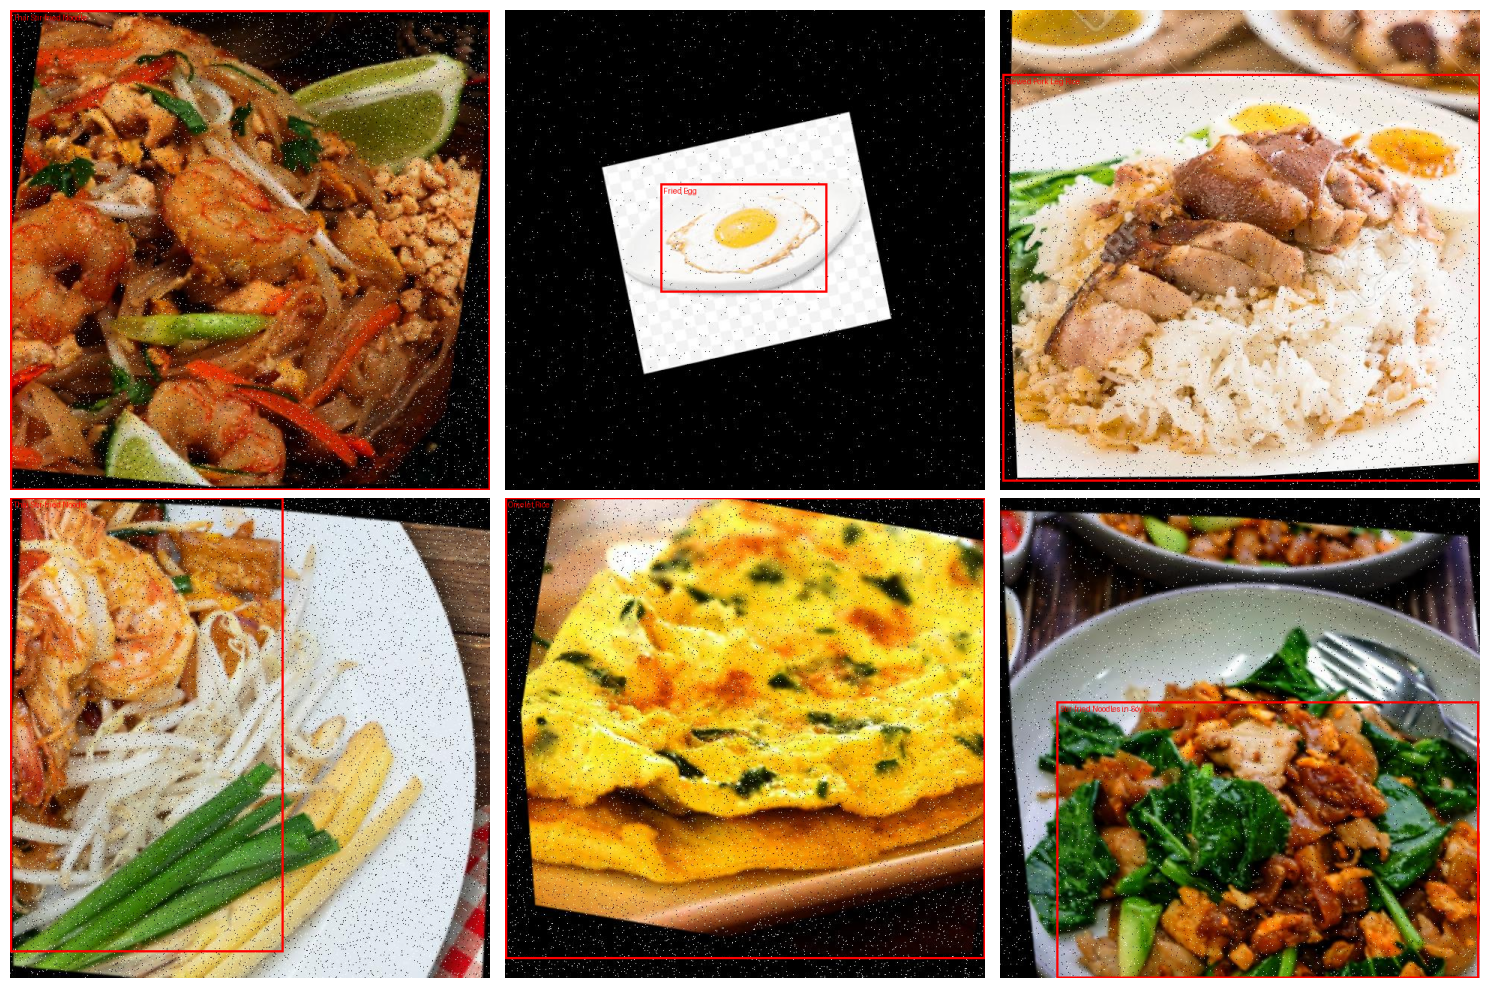

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

random.seed(0)
samples = random.sample(sorted((DATA_ROOT / 'train' / 'images').glob('*')), 6)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, img_path in zip(axes.flat, samples):
    img = Image.open(img_path).convert('RGB')
    w, h = img.size
    draw = ImageDraw.Draw(img)
    label_path = DATA_ROOT / 'train' / 'labels' / f'{img_path.stem}.txt'
    for line in label_path.read_text().splitlines() if label_path.exists() else []:
        c, x, y, bw, bh = map(float, line.split()[:5])
        box = [(x - bw / 2) * w, (y - bh / 2) * h, (x + bw / 2) * w, (y + bh / 2) * h]
        draw.rectangle(box, outline='red', width=3)
        draw.text((box[0] + 4, box[1] + 4), CLASS_NAMES[int(c)], fill='red')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()

## ขั้นที่ 6: เช็กว่าทุก class มีข้อมูลแคลอรี่

ทุก class ที่โมเดลรู้จักต้องมีแถวใน `data/nutrition.csv` ถ้าขาด ให้เพิ่มแถวใน repo แล้ว push ใหม่

> ค่าใน `nutrition.csv` ตอนเริ่มต้นเป็น **ค่าประมาณ** (`verified=false`) ควรตรวจสอบกับ
> [ฐานข้อมูลโภชนาการอาหารไทย สถาบันโภชนาการ ม.มหิดล](https://inmu.mahidol.ac.th/thaifcd/) แล้วแก้ `source` และ `verified=true`

In [ ]:
from calorie.nutrition import load_nutrition, missing_classes

NUTRITION = load_nutrition(PROJECT_DIR / 'data' / 'nutrition.csv')
missing = missing_classes(CLASS_NAMES, NUTRITION)
print('class ที่ยังไม่มีข้อมูลแคลอรี่:', missing or 'ไม่มี ครบแล้ว')

class ที่ยังไม่มีข้อมูลแคลอรี่: ไม่มี ครบแล้ว


## ขั้นที่ 7: Train โมเดล

**Transfer learning:** เราไม่ได้สร้างโมเดลจากศูนย์ แต่เริ่มจาก `yolo26n.pt` ที่ถูก train กับรูปทั่วไป (COCO 80 class) มาแล้ว
โมเดลนี้รู้จักขอบ สี และรูปทรงอยู่แล้ว เราแค่สอนเพิ่มให้แยกอาหารไทย จึงใช้ข้อมูลน้อยและ train เร็ว

| Parameter | ความหมาย |
|---|---|
| `epochs` | จำนวนรอบที่โมเดลเห็นข้อมูล train ครบทั้งชุด |
| `batch` | จำนวนรูปที่ประมวลผลพร้อมกันต่อ 1 step (ถ้าเจอ `CUDA out of memory` ให้ลดลง) |
| `imgsz` | ขนาดรูปที่ย่อ/ขยายก่อนเข้าโมเดล |
| `patience` | หยุด train อัตโนมัติถ้าผลไม่ดีขึ้นติดกัน N epoch (early stopping) |

**Overfitting** คืออาการที่โมเดล "ท่องจำ" รูป train ได้ แต่ทำรูปใหม่ไม่ได้ สังเกตจากกราฟหลัง train ถ้า loss ของ train ลดลงเรื่อยๆ แต่ของ val เริ่มสูงขึ้น แปลว่า overfit

`n` คือรุ่นเล็กสุด เร็วที่สุด ถ้าอยากได้ผลดีขึ้นลอง `yolo26s.pt` แล้วเทียบผล

In [ ]:
from ultralytics import YOLO

RUNS_DIR = DRIVE_DIR / 'runs'
RUN_NAME = 'thai-food-v1'

model = YOLO('yolo26n.pt')
model.train(data=str(DATA_YAML), epochs=60, imgsz=640, batch=16, patience=15,
            project=str(RUNS_DIR), name=RUN_NAME, exist_ok=True, seed=42)

New https://pypi.org/project/ultralytics/8.4.192 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/thai-food-calorie/datasets/thai_food-y98fg/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixu

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ad72dd4b8c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

**ถ้า session หลุดระหว่าง train:** รันขั้นที่ 2-4 ใหม่ แล้วรัน cell ด้านล่าง (เอา `#` ออก) เพื่อ train ต่อจากจุดเดิม

In [ ]:
# model = YOLO(str(RUNS_DIR / RUN_NAME / 'weights' / 'last.pt'))
# model.train(resume=True)

## ขั้นที่ 8: วัดผลโมเดล

| Metric | ความหมายแบบภาษาคน |
|---|---|
| **Precision** | ในบรรดาที่โมเดลบอกว่า "เป็นผัดไทย" ถูกจริงกี่ % (สูง = ทักผิดน้อย) |
| **Recall** | ผัดไทยที่มีอยู่จริงในรูป โมเดลหาเจอกี่ % (สูง = ตกหล่นน้อย) |
| **mAP50** | ความแม่นเฉลี่ยทุก class โดยนับว่าถูกถ้ากรอบทับกับคำตอบ ≥ 50% |
| **mAP50-95** | แบบเดียวกันแต่เข้มงวดขึ้น (กรอบต้องเป๊ะกว่า) |

ดู **confusion matrix** ด้วย จะเห็นว่าโมเดลสับสนเมนูไหนกับเมนูไหน เช่น ผัดซีอิ๊วกับราดหน้า ข้อมูลส่วนนี้ควรเขียนวิเคราะห์ลง README

In [ ]:
BEST = RUNS_DIR / RUN_NAME / 'weights' / 'best.pt'
best = YOLO(str(BEST))
metrics = best.val(data=str(DATA_YAML), split='test' if HAS_TEST else 'val')

print(f'Precision : {metrics.box.mp:.3f}')
print(f'Recall    : {metrics.box.mr:.3f}')
print(f'mAP50     : {metrics.box.map50:.3f}')
print(f'mAP50-95  : {metrics.box.map:.3f}')
print('\nmAP50-95 ราย class (จากแย่ไปดี):')
for i, m in sorted(enumerate(metrics.box.maps), key=lambda kv: kv[1]):
    print(f'   {CLASS_NAMES[i]:<35} {m:.3f}')

Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,392,165 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 63.1±23.4 MB/s, size: 59.1 KB)
val: Scanning /content/drive/MyDrive/thai-food-calorie/datasets/thai_food-y98fg/test/labels... 77 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 77/77 241.6it/s 0.3s
val: New cache created: /content/drive/MyDrive/thai-food-calorie/datasets/thai_food-y98fg/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.0it/s 2.5s
                   all         77         78      0.699      0.718      0.764      0.551
         BBQ Pork Rice          6          6      0.771      0.571      0.696      0.591
          Chicken Rice          5          5       0.93        0.4      0.635      0.364
             Fried Egg          6          6      0.723      0.833      0.927    

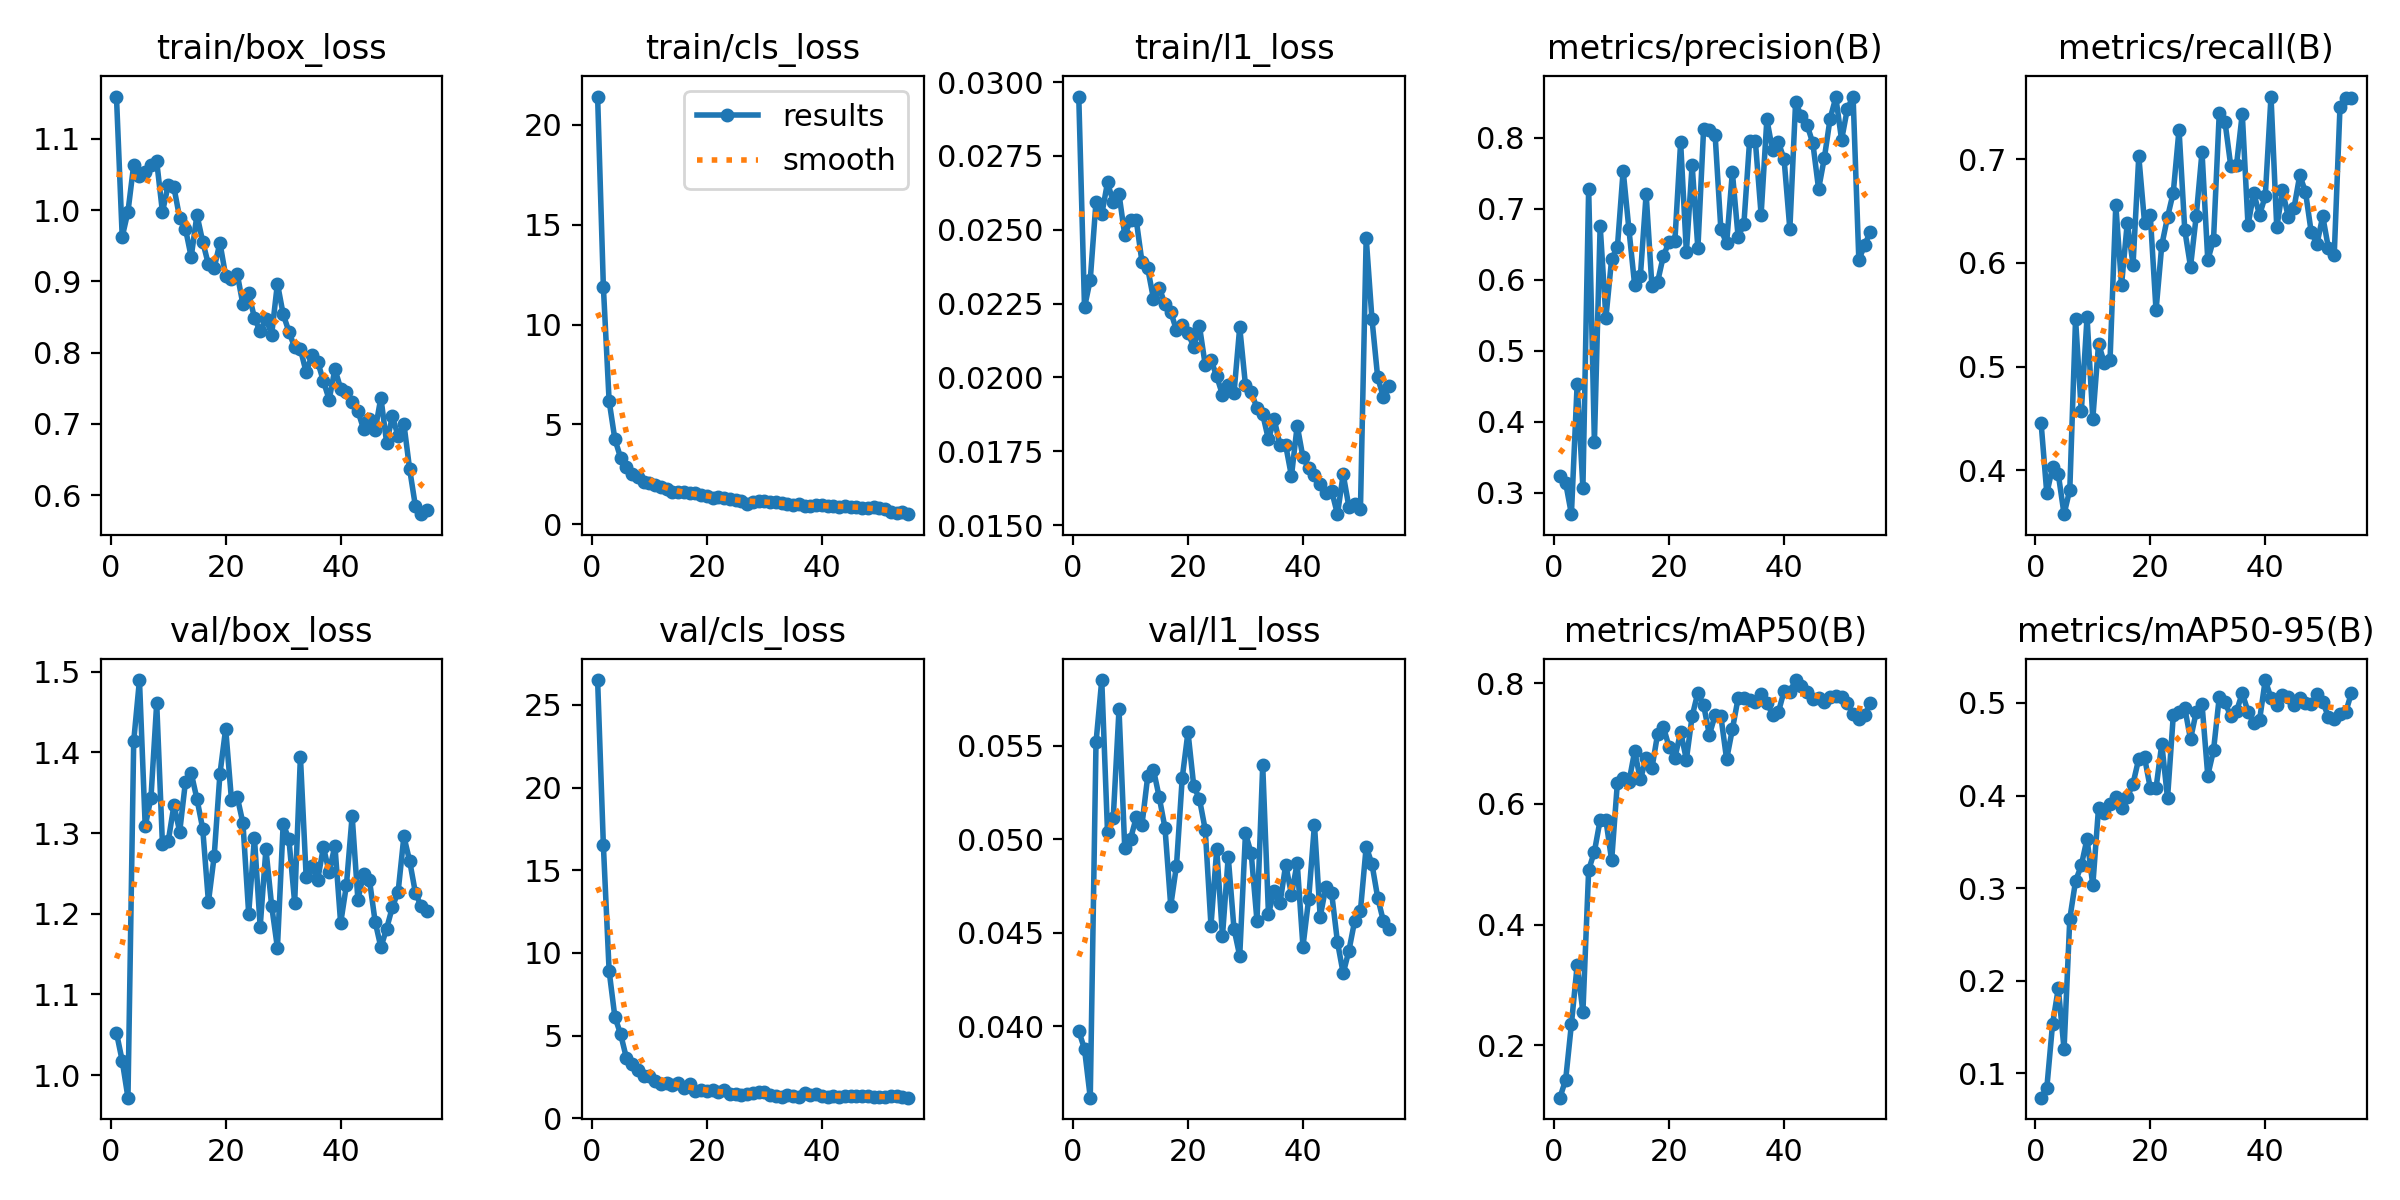

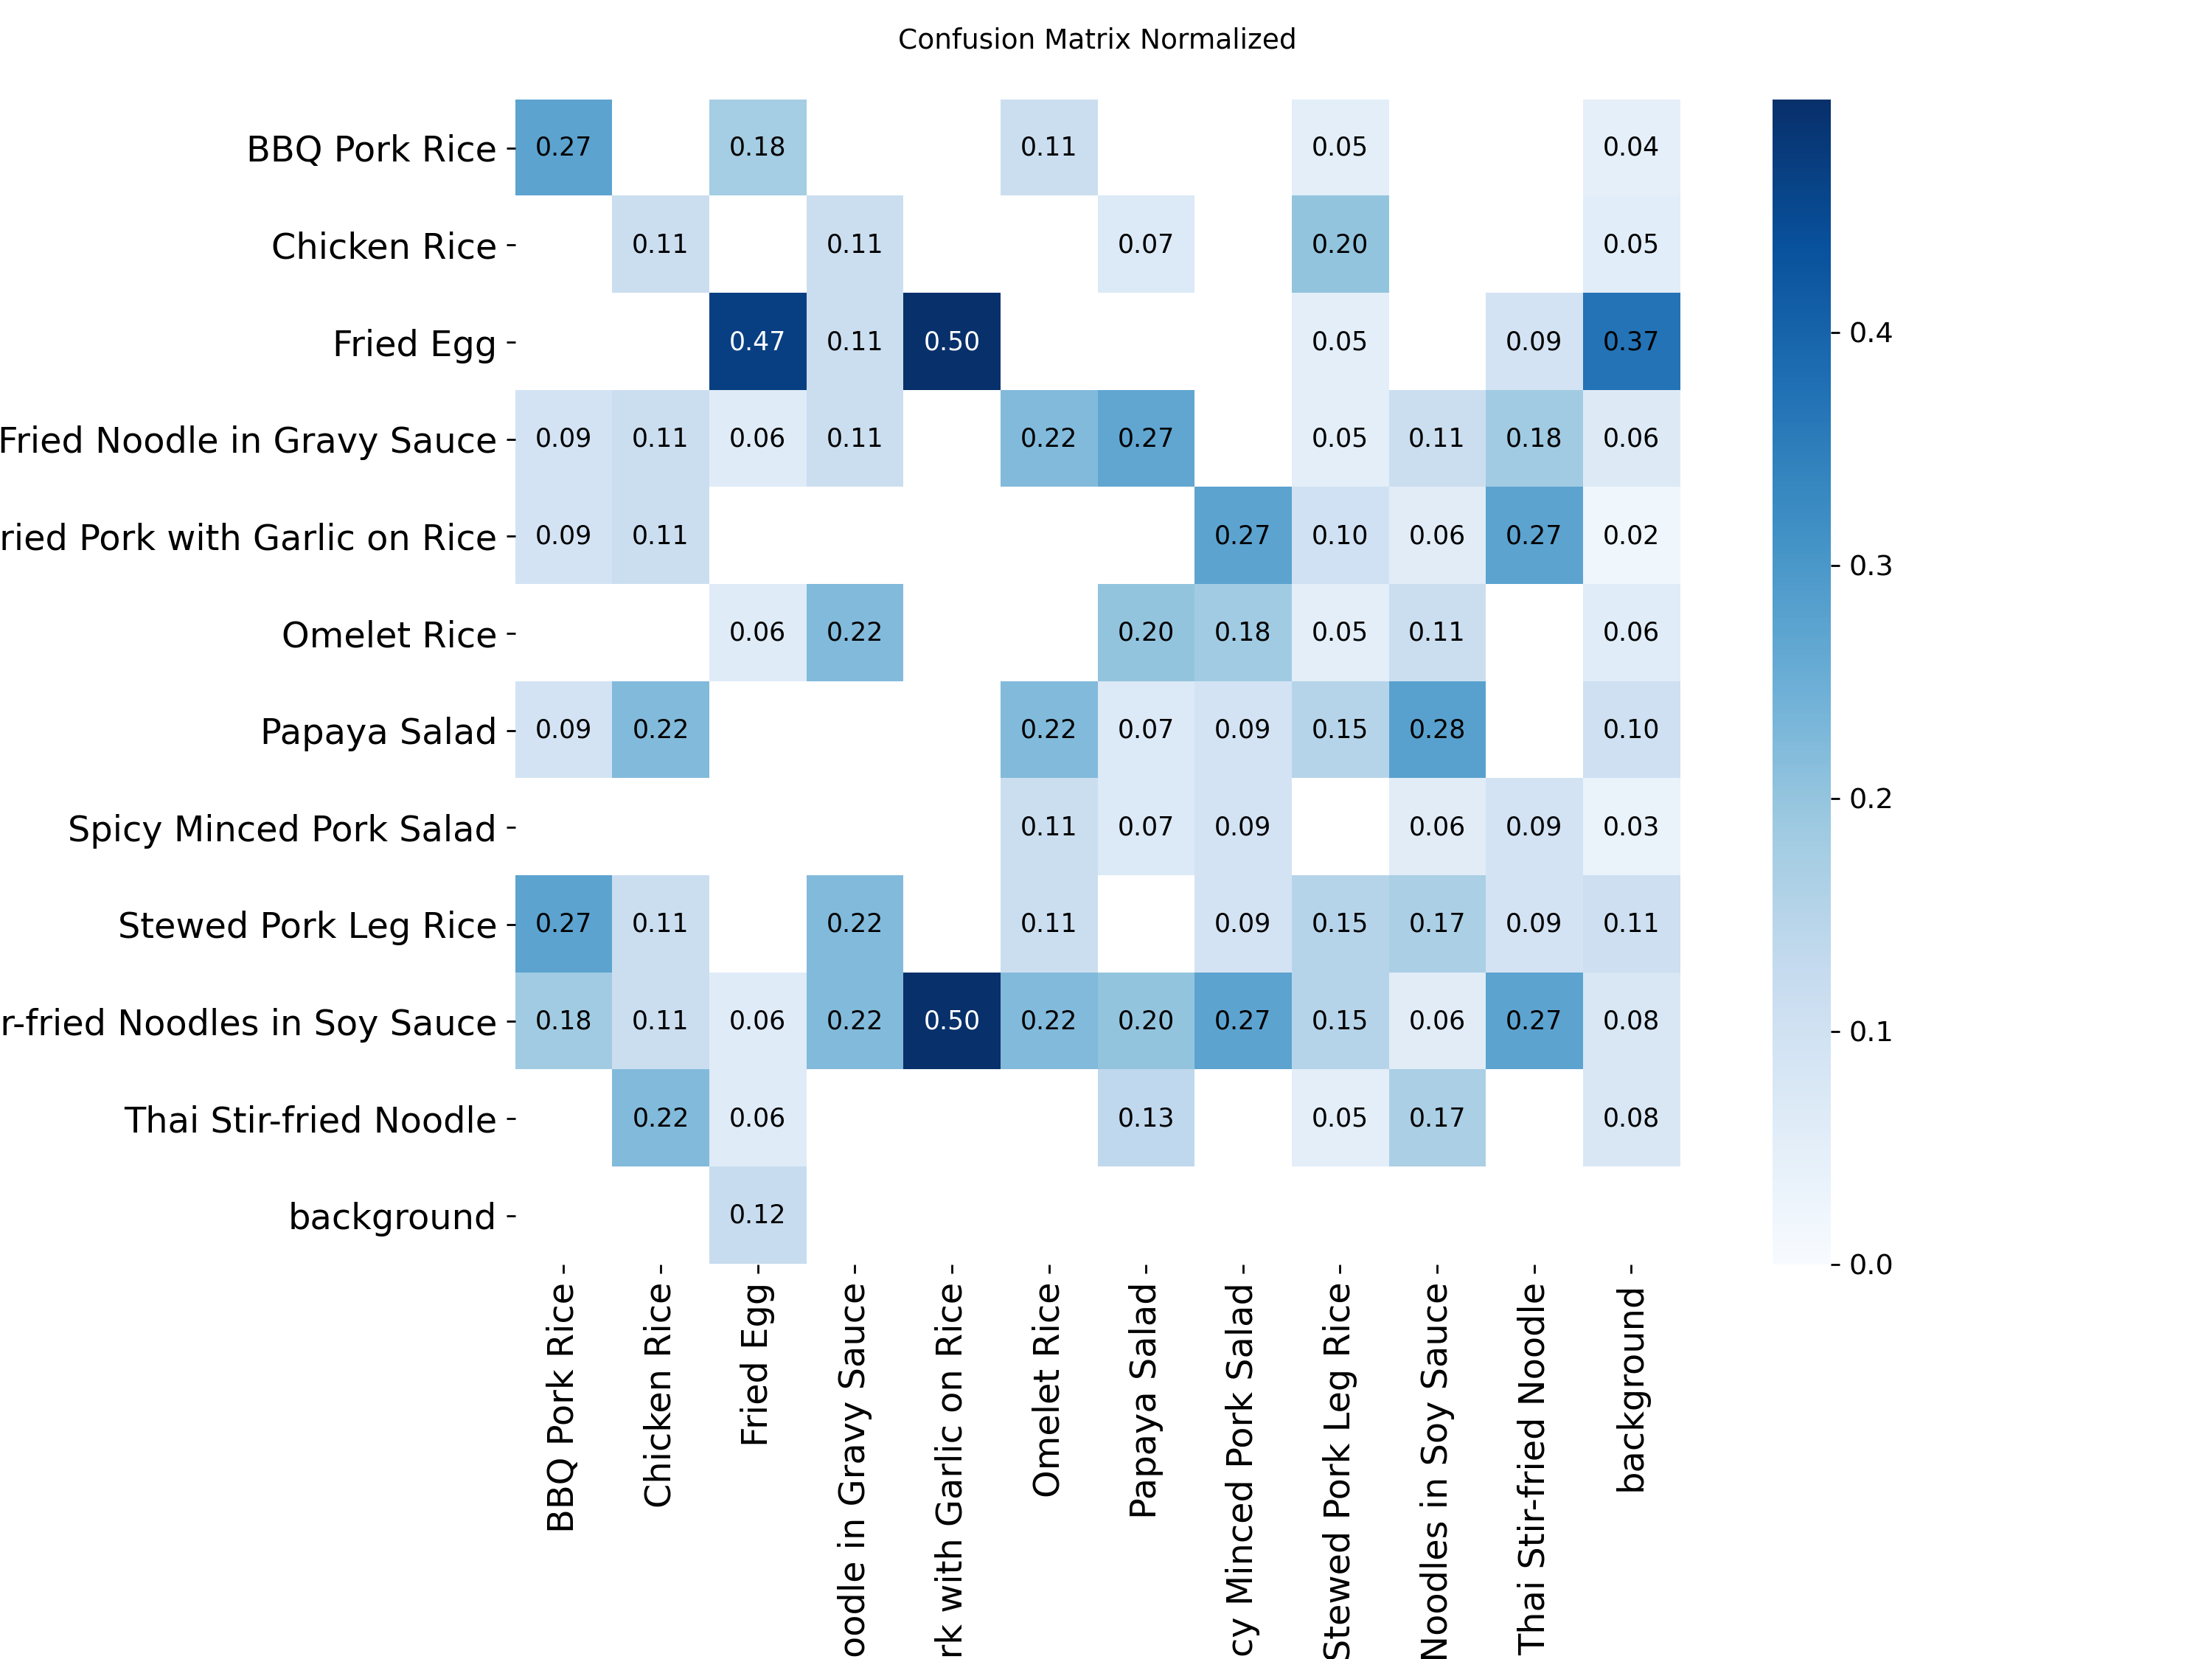

In [ ]:
from IPython.display import Image as IPImage, display

for name in ['results.png', 'confusion_matrix_normalized.png']:
    display(IPImage(filename=str(RUNS_DIR / RUN_NAME / name), width=900))

## ขั้นที่ 9: ทดสอบกับรูปที่คุณถ่ายเอง (สำคัญที่สุด)

รูปใน dataset มักถ่ายสวย แสงดี แต่รูปจริงจากมือถือเบลอ แสงเหลือง มีมือติด ความต่างนี้เรียกว่า **domain shift**
โมเดลที่ได้ mAP สูงกับ test set อาจทำได้แย่กับรูปจริง ส่วนนี้จะบอกความจริง

1. สร้างโฟลเดอร์ `MyDrive/thai-food-calorie/my_photos/` แล้วอัปโหลดรูปอาหารที่ถ่ายเอง
2. รูปจาก iPhone ที่เป็น `.HEIC` ให้แปลงเป็น `.jpg` ก่อน (หรือตั้งกล้องเป็น "Most Compatible")

In [ ]:
from calorie.estimator import detections_from_result, estimate_calories

MY_PHOTOS = DRIVE_DIR / 'my_photos'
MY_PHOTOS.mkdir(exist_ok=True)
photos = sorted(p for p in MY_PHOTOS.glob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
print(f'พบ {len(photos)} รูปใน {MY_PHOTOS}')

if photos:
    shown = photos[:6]
    results = best.predict([str(p) for p in shown], conf=0.4, verbose=False)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    for ax in axes.flat:
        ax.axis('off')
    for ax, photo, r in zip(axes.flat, shown, results):
        report = estimate_calories(detections_from_result(r), NUTRITION)
        ax.imshow(r.plot()[..., ::-1])
        ax.set_title(f'{photo.name}\n≈ {report.total_kcal:.0f} kcal ({report.low_kcal:.0f}-{report.high_kcal:.0f})')
    plt.tight_layout()

พบ 0 รูปใน /content/drive/MyDrive/thai-food-calorie/my_photos


## ขั้นที่ 10: วัดความแม่นของแคลอรี่กับค่าจริง

ส่วนนี้ทำให้โปรเจกต์ต่างจากคนอื่น เพราะคนส่วนใหญ่วัดแค่ mAP แต่ไม่เคยวัดว่า **แคลอรี่ที่บอกผู้ใช้ถูกแค่ไหน**

**หา ground truth ยังไง:**
- อาหารแช่แข็งหรือข้าวกล่องจากร้านสะดวกซื้อ มีแคลอรี่พิมพ์บนกล่อง ถ่ายรูปแล้วจดค่าได้เลย
- อาหารที่ทำเอง ชั่งน้ำหนักวัตถุดิบแล้วคำนวณจากฐานข้อมูล INMU

**วิธีเตรียม:**
1. อัปโหลดรูปไว้ที่ `MyDrive/thai-food-calorie/eval/images/`
2. สร้าง `MyDrive/thai-food-calorie/eval/ground_truth.csv` ตามแบบ `eval/ground_truth_template.csv` (คอลัมน์ `image,true_kcal,note`)

| Metric | ความหมาย |
|---|---|
| **MAE** | คลาดเคลื่อนเฉลี่ยกี่ kcal |
| **MAPE** | คลาดเคลื่อนเฉลี่ยกี่ % |
| **Range coverage** | ค่าจริงตกอยู่ในช่วงที่ระบบบอก (low-high) กี่ % ถ้าต่ำ แปลว่าช่วง ±25% แคบเกินไป |

In [ ]:
EVAL_DIR = DRIVE_DIR / 'eval'
EVAL_IMAGES = EVAL_DIR / 'images'
EVAL_TRUTH = EVAL_DIR / 'ground_truth.csv'
EVAL_OUT = EVAL_DIR / 'results.csv'

if EVAL_TRUTH.exists():
    !python scripts/evaluate_calories.py --model {BEST} --images {EVAL_IMAGES} --truth {EVAL_TRUTH} --out {EVAL_OUT}
else:
    print(f'ยังไม่มี {EVAL_TRUTH} ข้ามขั้นนี้ไปก่อนได้')

ยังไม่มี /content/drive/MyDrive/thai-food-calorie/eval/ground_truth.csv ข้ามขั้นนี้ไปก่อนได้


## ขั้นที่ 11: อัปโหลดโมเดลขึ้น Hugging Face Hub

เก็บโมเดลไว้บน Hub เพื่อให้ demo บน Hugging Face Spaces ดึงไปใช้ได้ และให้คนอื่นดาวน์โหลดได้ แก้ `HF_REPO` เป็นชื่อผู้ใช้ของคุณ

In [ ]:
from huggingface_hub import HfApi

HF_REPO = '<YOUR_HF_USERNAME>/thai-food-yolo'
api = HfApi(token=userdata.get('HF_TOKEN'))
api.create_repo(HF_REPO, repo_type='model', exist_ok=True)
api.upload_file(path_or_fileobj=str(BEST), path_in_repo='best.pt', repo_id=HF_REPO)
print(f'https://huggingface.co/{HF_REPO}')

HFValidationError: Repo id must use alphanumeric chars, '-', '_' or '.'. The name cannot start or end with '-' or '.' and the maximum length is 96: '<YOUR_HF_USERNAME>/thai-food-yolo'.

## ขั้นต่อไป

1. **Deploy demo:** สร้าง Space บน Hugging Face (SDK: Gradio) ใส่ไฟล์จาก repo นี้ แล้วตั้ง Variable `HF_MODEL_REPO` เป็นชื่อ repo โมเดลด้านบน (ดูขั้นตอนใน README)
2. **อัปเดต README:** ใส่ตัวเลข mAP, confusion matrix, ผลกับรูปที่ถ่ายเอง, MAE/MAPE ของแคลอรี่ และวิเคราะห์ว่าผิดตรงไหนเพราะอะไร
3. **ปรับปรุง:** เพิ่มรูปที่ถ่ายเองเข้า train set, ลอง `yolo26s.pt`, train นานขึ้น แล้วเทียบผลกับ v1
4. **Level 2:** เปลี่ยนเป็น segmentation (`yolo26n-seg.pt`) แล้วใช้พื้นที่อาหารเทียบกับจาน เพื่อประมาณขนาดจาน S/M/L